# Demand Forecasting Project from Scratch

### Objective:
Analyze historical sales data and forecast future demand to prevent inventory and revenue losses.

### Pipeline Overview:
1. **Data Extraction & Ingestion**
2. **Time-Series Preparation & Aggregation**
3. **Seasonality & Trend Analysis (Decomposition)**
4. **Forecasting (Holt-Winters Exponential Smoothing)**
5. **Validation & Metrics Evaluation**

In [7]:
# 1. Data Ingestion
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Unzip the raw file
!unzip -o /content/aswalmajor.zip -d /content/extracted_data

# Load the dataset
df = pd.read_csv('/content/extracted_data/sales_data_sample.csv', encoding='ISO-8859-1')
print(f"Loaded dataset with {df.shape[0]} rows and {df.shape[1]} columns.")

Archive:  /content/aswalmajor.zip
  inflating: /content/extracted_data/sales_data_sample.csv  
Loaded dataset with 2823 rows and 25 columns.


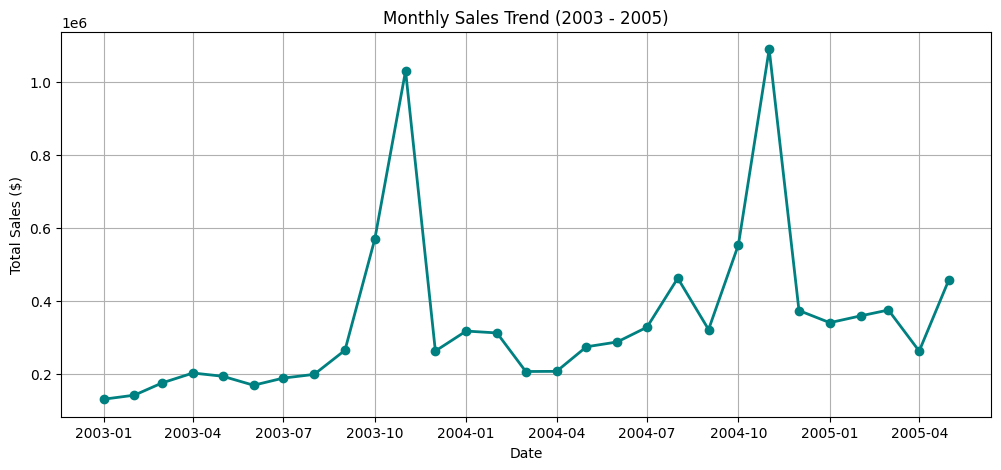

In [8]:
# 2. Time-Series Preparation
# Parse dates and group sales monthly
df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'], errors='coerce')
monthly_sales = df.groupby(df['ORDERDATE'].dt.to_period('M'))['SALES'].sum().reset_index()
monthly_sales['ORDERDATE'] = monthly_sales['ORDERDATE'].dt.to_timestamp()
monthly_sales.set_index('ORDERDATE', inplace=True)

# Plot original time-series trend
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales['SALES'], marker='o', color='teal', linewidth=2)
plt.title('Monthly Sales Trend (2003 - 2005)')
plt.xlabel('Date')
plt.ylabel('Total Sales ($)')
plt.grid(True)
plt.show()

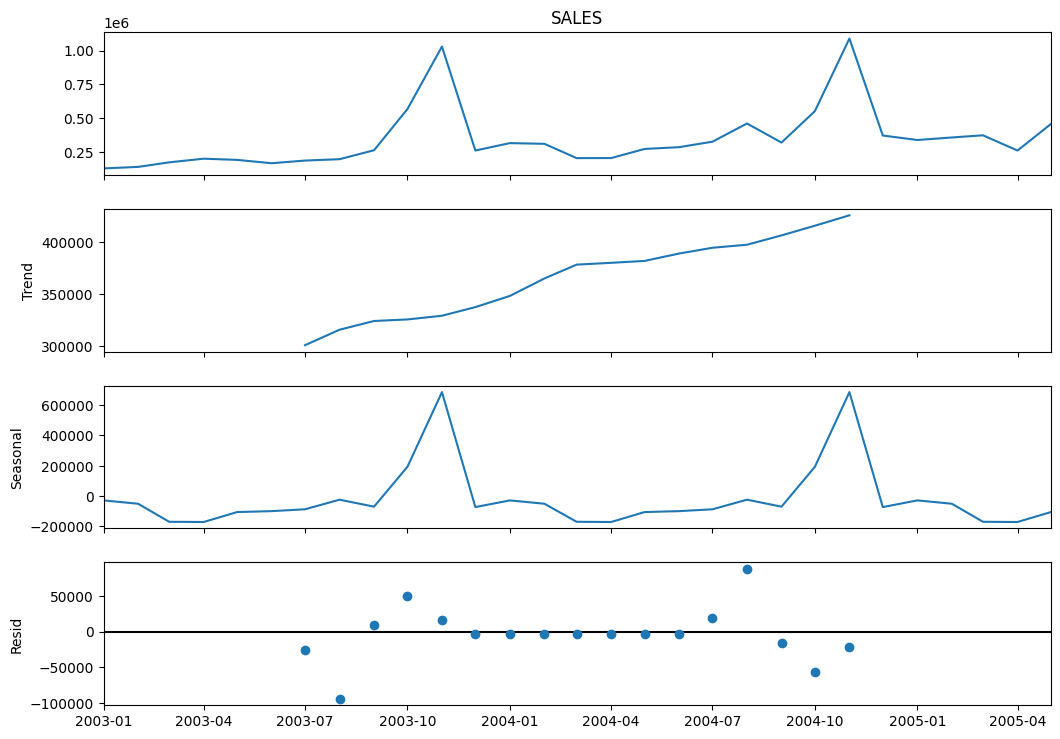

In [9]:
# 3. Seasonal Decomposition
decomposition = seasonal_decompose(monthly_sales['SALES'], model='additive', period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Forecast Accuracy Evaluation:
- RMSE: $98,017.43
- MAE: $81,747.83


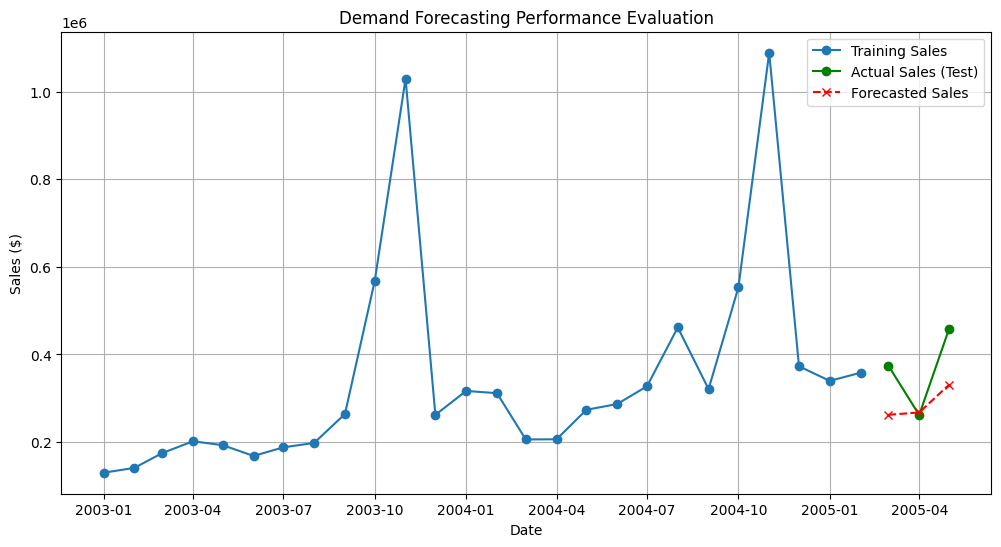

In [10]:
# 4. Forecasting Model & Evaluation
# Train-Test Split (3 months test to accommodate seasonality constraints of 2 full cycles)
train_data = monthly_sales.iloc[:-3]
test_data = monthly_sales.iloc[-3:]

# Fit Holt-Winters model with additive trend and seasonality
model = ExponentialSmoothing(
    train_data['SALES'],
    trend='add',
    seasonal='add',
    seasonal_periods=12,
    initialization_method='estimated'
).fit()

# Forecast future steps
predictions = model.forecast(steps=3)
predictions.index = test_data.index

# Metric Calculations
rmse = np.sqrt(mean_squared_error(test_data['SALES'], predictions))
mae = mean_absolute_error(test_data['SALES'], predictions)
print(f"Forecast Accuracy Evaluation:")
print(f"- RMSE: ${rmse:,.2f}")
print(f"- MAE: ${mae:,.2f}")

# Plotting predictions vs actual historical data
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['SALES'], label='Training Sales', marker='o')
plt.plot(test_data.index, test_data['SALES'], label='Actual Sales (Test)', color='g', marker='o')
plt.plot(test_data.index, predictions, label='Forecasted Sales', color='r', linestyle='--', marker='x')
plt.title('Demand Forecasting Performance Evaluation')
plt.xlabel('Date')
plt.ylabel('Sales ($)')
plt.legend()
plt.grid(True)
plt.show()

### 1. Unzipping the Dataset
We will extract the contents of the provided zip file to find the dataset for our time-series analysis.

In [1]:
!unzip -o /content/aswalmajor.zip -d /content/extracted_data
!ls -la /content/extracted_data

Archive:  /content/aswalmajor.zip
  inflating: /content/extracted_data/sales_data_sample.csv  
total 524
drwxr-xr-x 2 root root   4096 Oct 31 11:48 .
drwxr-xr-x 1 root root   4096 Oct 31 11:48 ..
-rw-r--r-- 1 root root 527958 Sep 20  2019 sales_data_sample.csv


### 2. Loading the Dataset
We load the `sales_data_sample.csv` into a Pandas DataFrame and display the basic structure and metadata.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load dataset
df = pd.read_csv('/content/extracted_data/sales_data_sample.csv', encoding='ISO-8859-1')
print(f"Dataset Dimensions: {df.shape}")
display(df.head())
df.info()

Dataset Dimensions: (2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


### 3. Date Parsing & Resampling (Time-Series Preparation)
To perform demand forecasting, we convert the date column, aggregate sales on a monthly frequency, and inspect the continuous series.

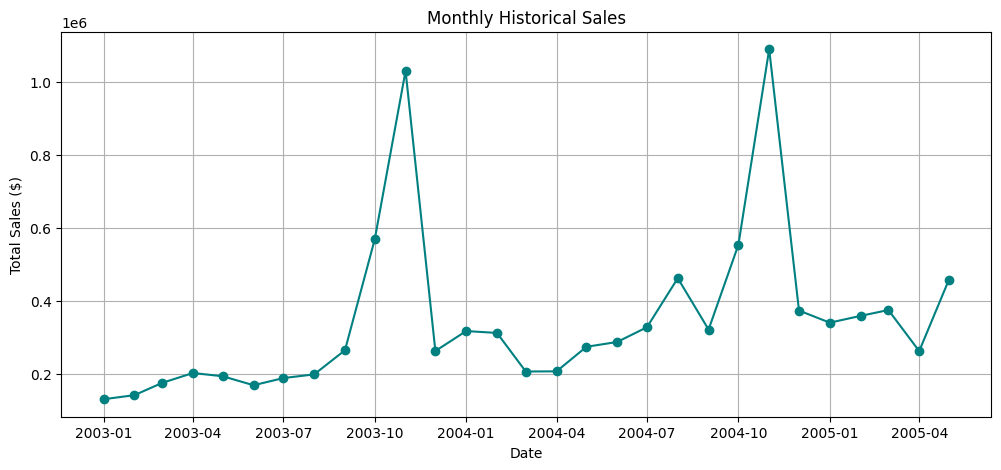

In [3]:
# Convert ORDERDATE to datetime
df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'], errors='coerce')

# Aggregate sales to monthly frequency
monthly_sales = df.groupby(df['ORDERDATE'].dt.to_period('M'))['SALES'].sum().reset_index()
monthly_sales['ORDERDATE'] = monthly_sales['ORDERDATE'].dt.to_timestamp()
monthly_sales.set_index('ORDERDATE', inplace=True)

# Visualize the monthly sales trend
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales['SALES'], marker='o', linestyle='-', color='teal')
plt.title('Monthly Historical Sales')
plt.xlabel('Date')
plt.ylabel('Total Sales ($)')
plt.grid(True)
plt.show()

### 4. Analyzing Seasonality and Trends
We decompose the time series into additive Trend, Seasonal, and Residual components to understand underlying patterns.

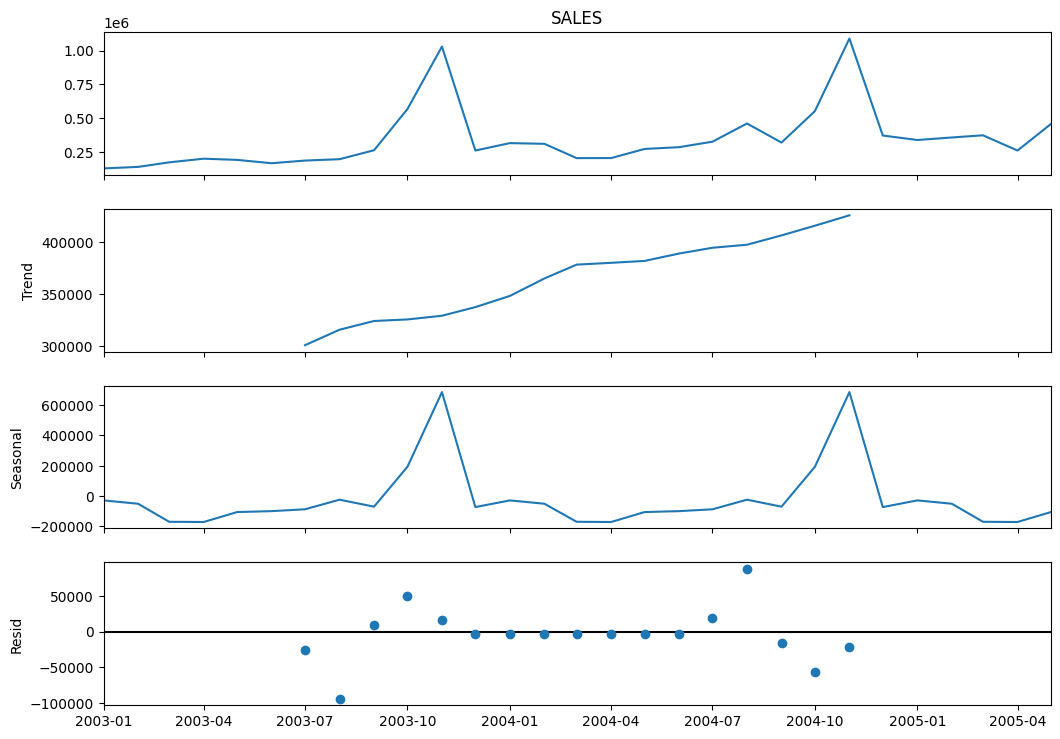

In [4]:
decomposition = seasonal_decompose(monthly_sales['SALES'], model='additive', period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.show()

### 5. Forecasting Techniques (Holt-Winters Exponential Smoothing)
We split the historical data into a training set and a testing set (last 6 months) to evaluate the model accuracy.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Root Mean Squared Error (RMSE): 98017.43
Mean Absolute Error (MAE): 81747.83


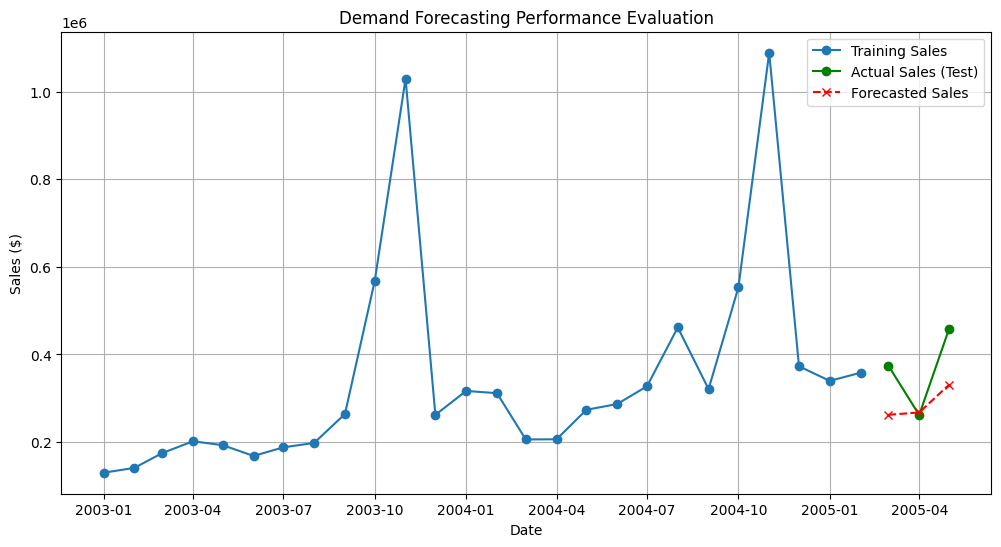

In [6]:
# Train-Test Split (using a 3-month test split so the training set has 26 months, fulfilling the 2 full seasonal cycles requirement)
train_data = monthly_sales.iloc[:-3]
test_data = monthly_sales.iloc[-3:]

# Fit Holt-Winters Exponential Smoothing model
model = ExponentialSmoothing(
    train_data['SALES'],
    trend='add',
    seasonal='add',
    seasonal_periods=12,
    initialization_method='estimated'
).fit()

# Forecast for the test period
predictions = model.forecast(steps=3)
predictions.index = test_data.index

# Calculate Forecast Metrics
rmse = np.sqrt(mean_squared_error(test_data['SALES'], predictions))
mae = mean_absolute_error(test_data['SALES'], predictions)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")

# Plot actuals vs predicted
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['SALES'], label='Training Sales', marker='o')
plt.plot(test_data.index, test_data['SALES'], label='Actual Sales (Test)', color='g', marker='o')
plt.plot(test_data.index, predictions, label='Forecasted Sales', color='r', linestyle='--', marker='x')
plt.title('Demand Forecasting Performance Evaluation')
plt.xlabel('Date')
plt.ylabel('Sales ($)')
plt.legend()
plt.grid(True)
plt.show()